Quinine
93 88
[-1.97083332 -1.96888709 -1.96694086 ... 13.9668659  13.96881213
 13.97075837]
Optimization terminated successfully.
         Current function value: 72043108520.371521
         Iterations: 107
         Function evaluations: 199


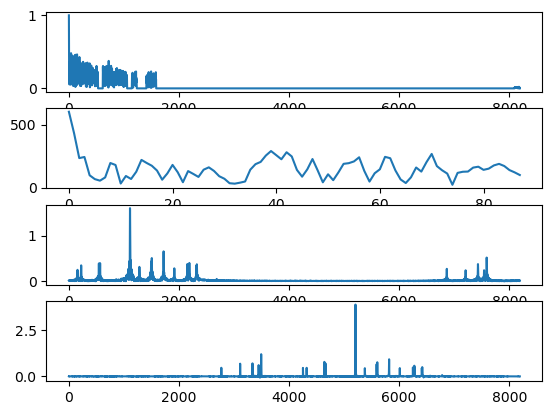

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import wandb
import matplotlib.pyplot as plt
from data.test_real_data_ps.evaluation import evaluate_signals
import math
import nmrglue as ng
from data.test_real_data_ps.adj_phase import acme
from torch.utils.data import Dataset, DataLoader
import scipy.io as scio
import time

def weighted_random_choice(weights):
    cdf = np.cumsum(weights)
    cdf = cdf / np.max(cdf)
    rnd = np.random.rand()
    for i, val in enumerate(cdf):
        if rnd < val:
            return i

def pad_num(num):
    mul = int(np.ceil(np.log2(num)))
    top = 2 ** mul
    if num < top:
        return top
    else:
        return num

def pad_data(data, top):
    length = len(data)
    if length < top:
        pad = top - length
        padded_data = np.pad(data, (0, pad), mode='constant')
        return padded_data
    else:
        return data
    
namelist = ['Quinine']
num = len(namelist) # 11
for nn in range(num):
    name = namelist[nn]
    print(name)

    filem = 'data/PS_real/' + name + '/multiplets1.txt'
    multiplets = np.loadtxt(filem)
    shift_ppm = multiplets[:, 0]
    a = multiplets[:, 1]

    filep = 'data/PS_real/' + name + '/peaks1.txt'
    peakwidths = np.loadtxt(filep)
    fwhm_Hz = np.mean(peakwidths)*math.pi

    psyche_dir = 'data/PS_real/' + name + '/PSYCHE.fid'
    dic, data = ng.varian.read(dir=psyche_dir, fid_file='fid', procpar_file='procpar')
    dic1 = ng.varian.read_procpar(psyche_dir+'/procpar')
    npo = int(dic1['np']['values'][0])/2
    at = float(dic1['at']['values'][0])
    reffrq = float(dic1['reffrq']['values'][0])
    sfrq = float(dic1['sfrq']['values'][0])
    sw = float(dic1['sw']['values'][0])
    sw1 = float(dic1['sw1']['values'][0])
    rp = float(dic1['rp']['values'][0])
    lp = float(dic1['lp']['values'][0])
    rfp = float(dic1['rfp']['values'][0])
    rfl = float(dic1['rfl']['values'][0])
    D = len(data)
    data = data*np.exp(-1j*rp*math.pi/180) # p0 phasing
    data = np.flipud(np.fft.fftshift(np.fft.fft(data)))
    data = data*np.exp(-1j*np.arange(D)*lp*math.pi/(D*180)) # p1 phasing
    data = np.fft.ifft(np.flipud(np.fft.fftshift(data)))

    fs=sfrq
    ref_f0=reffrq
    nfre = int(math.floor(sw/sw1 + 0.5))
    f0=reffrq
    Nf=int(npo)
    ni=int(math.floor(npo/nfre)) 
    print(ni, nfre)

    sp=(rfp-rfl) / sfrq
    ppm=np.linspace(sp,(sw / sfrq + sp), 8192)
    scio.savemat('./data/spec_ps_'+ name +'_ppm.mat', {'ppm': ppm})
    print(ppm)

    # Access the specific structure and field
    reference_signal=np.fft.fft(data,Nf)
    reference_signal = reference_signal.reshape((1, -1))
    phcf = [0,0]

    [reference_signal,phc0a,phc1a] = acme(reference_signal, phcf)
    reference_signal_mask = np.fft.ifft(reference_signal).reshape((ni, nfre))

    mask = np.zeros((ni, nfre))
    sample_rate = 0.161
    p = int(np.round(sample_rate * ni))  

    wx = np.linspace(start = 0, stop = ni-1, num = ni)
    weights = np.exp(-1.2*wx)

    selected_indices = []
    num = 0
    for _ in range(p):
        selected_index = weighted_random_choice(weights)+1
        num = num + selected_index
        selected_indices.append(num-1)
        weights = np.concatenate((weights[:(selected_index-1)], weights[selected_index:]))

    selected_indices[0]=0
    selected_indices[-1]=ni-1
    mask[selected_indices, :] = 1

    x = reference_signal_mask * mask
    x = x.flatten()
    x = x.reshape(Nf)
    x = x / np.abs(x).max()

    N = pad_num(Nf)
    xw = np.fft.fft(x, N)
    xw /= np.sqrt(N)
    
    x = pad_data(x, N)

    y = reference_signal_mask
    y = y.flatten()
    y = y.reshape(Nf)
    y = y / np.abs(y).max()
    reference_signal = np.fft.fft(y ,N)
    reference_signal /=np.sqrt(N)

    fid_nus_1D = np.reshape(x, (1, -1))
    xw = np.reshape(xw, (1, -1))
    reference_signal = np.reshape(reference_signal, (1, -1))


plt.figure(1)
plt.subplot(4, 1, 1)
plt.plot(np.abs(fid_nus_1D[0]))
plt.subplot(4, 1, 2)
plt.plot(np.abs(reference_signal_mask[0]))
plt.subplot(4, 1, 3)
plt.plot(np.abs(xw[0]))
plt.subplot(4, 1, 4)
plt.plot(np.real(np.fft.fftshift(reference_signal[0])))

pad_shape= (8192, 256)
pad_height= 0
pad_width= 0


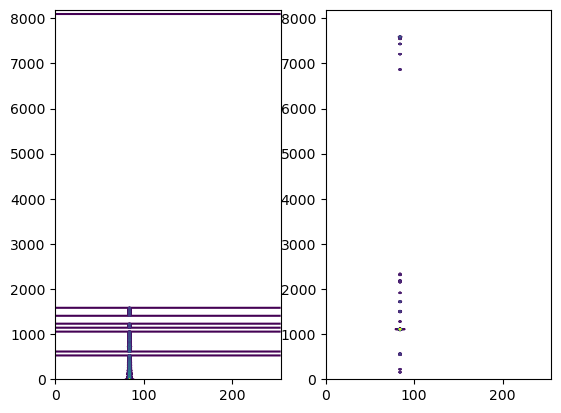

In [ ]:
import torch

def pad_data(data, block_size):
    height, width = data.shape
    pad_height = (block_size - height % block_size) % block_size
    pad_width = (block_size - width % block_size) % block_size
    padded_data = np.pad(data, ((0, pad_height), (0, pad_width)), mode='constant', constant_values=0)
    return padded_data, pad_height, pad_width


def block_data(data, block_size):
    padded_data, pad_height, pad_width = pad_data(data, block_size)
    height, width = padded_data.shape
    num_blocks_vertical = height // block_size
    num_blocks_horizontal = width // block_size
    blocks = np.empty((num_blocks_vertical * num_blocks_horizontal, block_size, block_size), dtype=padded_data.dtype)
    idx = 0
    for i in range(num_blocks_vertical):
        for j in range(num_blocks_horizontal):
            block = padded_data[i*block_size:(i+1)*block_size, j*block_size:(j+1)*block_size]
            blocks[idx] = block
            idx += 1
    return blocks, padded_data.shape, pad_height, pad_width


def reconstruct_data(blocks, pad_shape, pad_height, pad_width):
    height, width = pad_shape
    num_blocks, block_height, block_width = blocks.shape
    num_blocks_vertical = height // block_height
    num_blocks_horizontal = width // block_width
    reconstructed_data = np.empty((height, width), dtype=blocks.dtype)
    idx = 0
    for i in range(num_blocks_vertical):
        for j in range(num_blocks_horizontal):
            block = blocks[idx]
            reconstructed_data[i*block_height:(i+1)*block_height, j*block_width:(j+1)*block_width] = block
            idx += 1
    final_data = reconstructed_data[:height if not pad_height else -pad_height, :width if not pad_width else -pad_width]
    return final_data


dim = 1
N1 = 256 
max_J = 1

J = np.random.randint(1, max_J + 1, size=(dim, 1))  
mask = np.zeros((dim, max_J))
mask[np.arange(dim), J.ravel() - 1] = 1  
mask = np.cumsum(mask, axis=1)
ph = np.random.uniform(0.0, 0, size=(dim, max_J)) 
A = np.random.uniform(0.05, 1.0, size=(dim, max_J)) 
w = np.random.uniform(0.3, 0.5, size=(dim, max_J))
sgm = np.random.uniform(399, 400, size=(dim, max_J))  
t1 = np.arange(N1)  
A = np.multiply(A, mask)
x1 = A[..., None] * np.exp(-t1 / sgm[..., None]) * np.exp(1j * 2 * np.pi * w[..., None] * t1)
clean_xn = np.sum(x1, axis=1)
spec = np.fft.fft(clean_xn)
norm_spec = spec / np.max(spec)

GT_label = np.matmul(reference_signal.T, norm_spec)
Full_FID = np.fft.ifft(GT_label, axis=0)
NUS_FID = np.matmul(fid_nus_1D.T, norm_spec)
U = (NUS_FID != 0)

input_size = 256
phase_input, pad_shape, pad_height, pad_width = block_data(GT_label, input_size)
print('pad_shape=', pad_shape)
print('pad_height=', pad_height)
print('pad_width=', pad_width)

NUS_FID = np.multiply(U, Full_FID)
NOISE_input = np.fft.fft(NUS_FID, axis=0)

plt.figure(2)
plt.subplot(1, 2, 1)
plt.contour(np.abs(NUS_FID), levels = 50)
plt.subplot(1, 2, 2)
plt.contour(np.abs(GT_label), levels = 50)

NUS_FID, _, _, _ = block_data(NUS_FID, input_size)
NOISE_input, _, _, _ = block_data(NOISE_input, input_size)
GT_label, _, _, _ = block_data(GT_label, input_size)
block_num = phase_input.shape[0]

max_amp = np.max(np.abs(NOISE_input))

NUS_FID = torch.complex(torch.from_numpy(NUS_FID.real).float(), torch.from_numpy(NUS_FID.imag).float()) / (max_amp * (1 / sample_rate))
NOISE_input = torch.complex(torch.from_numpy(NOISE_input.real).float(), torch.from_numpy(NOISE_input.imag).float()) / (max_amp)
GT_label = torch.complex(torch.from_numpy(GT_label.real).float(), torch.from_numpy(GT_label.imag).float()) / (max_amp * (1 / sample_rate))
factor_matrix = GT_label

LR = NUS_FID.unsqueeze(1)
SR = torch.cat((NOISE_input.real.unsqueeze(1), NOISE_input.imag.unsqueeze(1)), dim=1)
HR = torch.cat((GT_label.real.unsqueeze(1), GT_label.imag.unsqueeze(1)), dim=1)
WR = factor_matrix

val_data =  {'LR': LR, 'HR': HR, 'SR': SR, 'WR': WR}


In [ ]:
import os
import torch
import logging
import random
import numpy as np
import scipy.io as scio
from tqdm import tqdm
from torch.utils.data import Dataset
import data as Data
import model as Model
import argparse
import logging
import core.logger as Logger
import core.metrics as Metrics
import os
from data import dataset
import matplotlib.pyplot as plt

parser = argparse.ArgumentParser()
parser.add_argument('-c', '--config', type=str, default='config/sr_sr3_256_256_val.json',
                    help='JSON file for configuration')
parser.add_argument('-p', '--phase', type=str, choices=['train', 'val'], 
                    help='Run either train(training) or val(generation)', default='val')
parser.add_argument('-gpu', '--gpu_ids', type=str, default=None)
parser.add_argument('-debug', '-d', action='store_true')
parser.add_argument('-enable_wandb', action='store_true')
parser.add_argument('-log_wandb_ckpt', action='store_true')
parser.add_argument('-log_eval', action='store_true')


args =parser.parse_known_args()[0]
opt = Logger.parse(args)
opt = Logger.dict_to_nonedict(opt)

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True
Logger.setup_logger(None, opt['path']['log'],
                    'train', level=logging.INFO, screen=True)
Logger.setup_logger('val', opt['path']['log'], 'val', level=logging.INFO)
logger = logging.getLogger('base')
logger.info(Logger.dict2str(opt))

diffusion = Model.create_model(opt)
logger.info('Initial Model Finished')

current_step = diffusion.begin_step
current_epoch = diffusion.begin_epoch
n_iter = opt['train']['n_iter']

if opt['path']['resume_state']:
    logger.info('Resuming training from epoch: {}, iter: {}.'.format(
        current_epoch, current_step))

diffusion.set_new_noise_schedule(
    opt['model']['beta_schedule'][opt['phase']], schedule_phase=opt['phase'])

In [ ]:
diffusion = Model.create_model(opt)
avg_mse = 0.0
result_path = '{}/{}'.format(opt['path']['results'], 100)
os.makedirs(result_path, exist_ok=True)
diffusion.set_new_noise_schedule(opt['model']['beta_schedule']['val'], schedule_phase='val')

val_data = diffusion.set_device(val_data)
diffusion.feed_data(val_data)
diffusion.test(continous=False, pnp_mode='nus',
               pad_shape=pad_shape, pad_height=pad_height, pad_width=pad_width)

visuals = diffusion.get_current_visuals()


try:
    if block_num is not None:
        fake_img = reconstruct_data(torch.complex(visuals['INF'][0 : block_num , 0], visuals['INF'][0 : block_num , 1]).cpu().numpy(), pad_shape, pad_height, pad_width)
        sr_img = reconstruct_data(torch.complex(visuals['SR'][-block_num : , 0], visuals['SR'][-block_num :, 1]).cpu().numpy(), pad_shape, pad_height, pad_width)
        hr_img = reconstruct_data(torch.complex(visuals['HR'][0 : block_num , 0], visuals['HR'][0 : block_num , 1]).cpu().numpy(), pad_shape, pad_height, pad_width)
        lr_img = reconstruct_data(visuals['LR'][0 : block_num].squeeze().float().cpu().numpy(), pad_shape, pad_height, pad_width)

except NameError:
    fake_img = torch.complex(visuals['INF'][0, 0], visuals['INF'][0, 1]).squeeze().float().cpu().numpy()
    sr_img = torch.complex(visuals['SR'][-1, 0], visuals['SR'][-1, 1]).squeeze().float().cpu().numpy()
    hr_img = torch.complex(visuals['HR'][0, 0], visuals['HR'][0, 1]).squeeze().float().cpu().numpy()
    lr_img = visuals['LR'][0].squeeze().float().cpu().numpy()


/mnt/DATA1/shaojie/anaconda3/envs/pyt/lib/python3.10/site-packages/scipy/signal/_peak_finding.py:266: ComplexWarning: Casting complex values to real discards the imaginary part
  value = np.asarray(value, order='C', dtype=np.float64)


rmsd =  0.0075946655


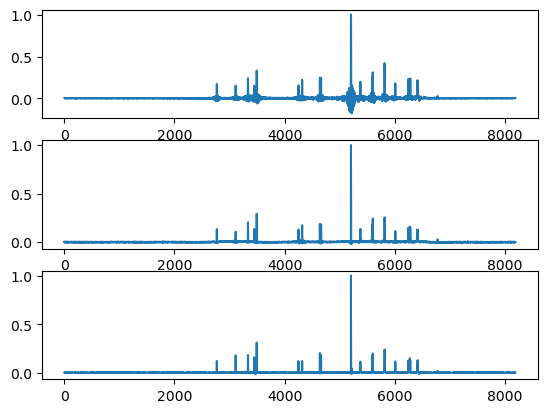

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

scio.savemat('./data/recon_spec_ps_quinine.mat', {'recon_spec': sr_img})
scio.savemat('./data/label_spec_ps_quinine.mat', {'label_spec': hr_img, 'ppm': ppm})
scio.savemat('./data/input_spec_ps_quinine.mat', {'input_spec': fake_img})

peaks, properties = find_peaks(norm_spec.squeeze(), height=0.5, distance=50)  

nus_spec = np.fft.fftshift(fake_img[:, peaks])
recon_spec = np.fft.fftshift(sr_img[:, peaks])
ideal_spec = np.fft.fftshift(hr_img[:, peaks])

plt.figure(1)
plt.subplot(3, 1, 1)
plt.plot(np.real(nus_spec) / np.max(np.real(nus_spec)))
plt.subplot(3, 1, 2)
plt.plot(np.real(recon_spec) / np.max(np.real(recon_spec)))
plt.subplot(3, 1, 3)
plt.plot(np.real(ideal_spec) / np.max(np.real(ideal_spec)))

rmsd = np.sqrt(np.mean((np.real(ideal_spec) / np.max(np.real(ideal_spec)) - np.real(recon_spec) / np.max(np.real(recon_spec)))**2))
print('rmsd = ', rmsd)